# Análisis exploratorio de la carga de tuberculosis en las Américas, 2000-2024

Datos: *WHO TB burden estimates*, Programa Mundial de Tuberculosis de la Organización Mundial de la Salud (OMS).
Se trabaja con la región de las Américas (código AMR): 46 países y territorios entre 2000 y 2024.

**Preguntas:**
1. ¿Cómo se distribuye la carga de tuberculosis entre las subregiones de las Américas y qué países concentran los valores más altos?
2. ¿Los países con más casos de tuberculosis también tienen más muertes, y de qué depende la proporción de personas que mueren?
3. ¿Cómo ha cambiado la incidencia de tuberculosis entre 2000 y 2024?

## 1. Carga de los datos

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# Mostrar todas las columnas sin cortar la salida
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
# Crear las carpetas donde se guardan las figuras
os.makedirs("figuras/descartadas", exist_ok=True)

# Cargar el archivo original de la OMS y ver su tamaño (filas, columnas)
tb = pd.read_csv("datos/TB_burden_countries_2026-11-12.csv")
tb.shape

(5347, 50)

In [2]:
# Primeras filas del archivo original
tb.head()

,country,iso2,iso3,iso_numeric,g_whoregion,year,e_pop_num,e_inc_100k,e_inc_100k_lo,e_inc_100k_hi,e_inc_num,e_inc_num_lo,e_inc_num_hi,e_tbhiv_prct,e_tbhiv_prct_lo,e_tbhiv_prct_hi,e_inc_tbhiv_100k,e_inc_tbhiv_100k_lo,e_inc_tbhiv_100k_hi,e_inc_tbhiv_num,e_inc_tbhiv_num_lo,e_inc_tbhiv_num_hi,e_mort_exc_tbhiv_100k,e_mort_exc_tbhiv_100k_lo,e_mort_exc_tbhiv_100k_hi,e_mort_exc_tbhiv_num,e_mort_exc_tbhiv_num_lo,e_mort_exc_tbhiv_num_hi,e_mort_tbhiv_100k,e_mort_tbhiv_100k_lo,e_mort_tbhiv_100k_hi,e_mort_tbhiv_num,e_mort_tbhiv_num_lo,e_mort_tbhiv_num_hi,e_mort_100k,e_mort_100k_lo,e_mort_100k_hi,e_mort_num,e_mort_num_lo,e_mort_num_hi,cfr,cfr_lo,cfr_hi,cfr_pct,cfr_pct_lo,cfr_pct_hi,c_newinc_100k,c_cdr,c_cdr_lo,c_cdr_hi
0,Afghanistan,AF,AFG,4,EMR,2000,20130323,148.0,46.0,1510.0,30000.0,9200.0,305000.0,0.02,NaN,NaN,0.03,0.0,0.07,5.0,0.0,15.0,50.0,32.0,70.0,10000.0,6500.0,14000.0,0.02,0.0,0.05,3.0,0.0,9.0,50.0,32.0,70.0,10000.0,6500.0,14000.0,0.34,0.19,0.50,34.0,19.0,50.0,35.0,24.0,2.3,77.0
1,Afghanistan,AF,AFG,4,EMR,2001,20284311,175.0,66.0,1320.0,35000.0,13000.0,267000.0,0.01,NaN,NaN,0.03,0.0,0.08,5.0,0.0,16.0,55.0,37.0,76.0,11000.0,7600.0,15000.0,0.02,0.0,0.05,3.0,0.0,9.0,55.0,37.0,76.0,11000.0,7600.0,15000.0,0.32,0.20,0.46,32.0,20.0,46.0,50.0,29.0,3.8,76.0
2,Afghanistan,AF,AFG,4,EMR,2002,21378110,197.0,83.0,1140.0,42000.0,18000.0,245000.0,0.01,NaN,NaN,0.03,0.0,0.08,6.0,0.0,18.0,59.0,41.0,80.0,13000.0,8700.0,17000.0,0.02,0.0,0.05,3.0,0.0,10.0,59.0,41.0,80.0,13000.0,8700.0,17000.0,0.30,0.19,0.42,30.0,19.0,42.0,65.0,33.0,5.6,78.0
3,Afghanistan,AF,AFG,4,EMR,2003,22733047,215.0,97.0,992.0,49000.0,22000.0,225000.0,0.01,NaN,NaN,0.03,0.0,0.09,7.0,1.0,21.0,68.0,48.0,92.0,15000.0,11000.0,21000.0,0.02,0.0,0.05,4.0,0.0,12.0,68.0,48.0,92.0,15000.0,11000.0,21000.0,0.32,0.21,0.44,32.0,21.0,44.0,61.0,28.0,6.1,63.0
4,Afghanistan,AF,AFG,4,EMR,2004,23560660,228.0,109.0,862.0,54000.0,26000.0,203000.0,0.01,NaN,NaN,0.03,0.0,0.10,8.0,1.0,24.0,67.0,47.0,89.0,16000.0,11000.0,21000.0,0.02,0.0,0.06,4.0,0.0,13.0,67.0,47.0,89.0,16000.0,11000.0,21000.0,0.29,0.20,0.40,29.0,20.0,40.0,78.0,34.0,9.1,72.0


In [3]:
# Número de países y rango de años; países escritos de varias formas (nombres frente a códigos ISO3)
tb["country"].nunique(), tb["iso3"].nunique(), tb["year"].min(), tb["year"].max()

(217, 217, np.int64(2000), np.int64(2024))

In [4]:
# Registros por región de la OMS
tb["g_whoregion"].value_counts()

g_whoregion
EUR    1345
AFR    1164
AMR    1115
WPR     925
EMR     550
SEA     248
Name: count, dtype: int64

## 2. Filtro de la región de las Américas

In [5]:
# Quedarse solo con la región de las Américas (AMR) en una copia independiente
am = tb[tb["g_whoregion"] == "AMR"].copy()
# Verificar el tamaño y que solo quede la región AMR
am.shape, am["g_whoregion"].unique()

((1115, 50),
 <StringArray>
 ['AMR']
 Length: 1, dtype: str)

## 3. Columnas vacías

In [6]:
# Identificar las columnas donde todos los valores están vacíos
vacias = am.columns[am.isna().all()].tolist()
am[vacias].isna().sum()

e_tbhiv_prct_lo    1115
e_tbhiv_prct_hi    1115
dtype: int64

In [7]:
# Eliminar las columnas completamente vacías
am = am.dropna(axis=1, how="all")
am.shape

(1115, 48)

## 4. Selección de columnas y nombres más intuitivos

In [8]:
# Diccionario: nombre original -> nombre nuevo de las 17 columnas que se conservan
nombres = {
    "country": "pais",
    "iso3": "iso3",
    "year": "anio",
    "e_pop_num": "poblacion",
    "e_inc_100k": "incidencia_100k",
    "e_inc_100k_lo": "incidencia_100k_inf",
    "e_inc_100k_hi": "incidencia_100k_sup",
    "e_mort_100k": "mortalidad_100k",
    "e_mort_100k_lo": "mortalidad_100k_inf",
    "e_mort_100k_hi": "mortalidad_100k_sup",
    "e_tbhiv_prct": "porc_casos_con_vih",
    "e_inc_tbhiv_100k": "incidencia_con_vih_100k",
    "e_mort_tbhiv_100k": "mortalidad_con_vih_100k",
    "e_mort_exc_tbhiv_100k": "mortalidad_sin_vih_100k",
    "c_newinc_100k": "casos_notificados_100k",
    "c_cdr": "tasa_deteccion",
    "cfr": "letalidad"
}
# Cambiar los nombres de las columnas
am = am.rename(columns=nombres)
am.shape

(1115, 48)

`rename` solo cambia los nombres: el conjunto sigue con 48 columnas. Falta seleccionar las 17 columnas relevantes.

In [9]:
# Seleccionar solo las 17 columnas del diccionario
am = am[list(nombres.values())]
am.shape

(1115, 17)

## 5. Diagnóstico de valores faltantes

In [10]:
# Número de valores faltantes por columna
am.isna().sum()

pais                         0
iso3                         0
anio                         0
poblacion                    0
incidencia_100k              0
incidencia_100k_inf          0
incidencia_100k_sup          0
mortalidad_100k              0
mortalidad_100k_inf          0
mortalidad_100k_sup          0
porc_casos_con_vih         390
incidencia_con_vih_100k    390
mortalidad_con_vih_100k    390
mortalidad_sin_vih_100k    390
casos_notificados_100k      81
tasa_deteccion             147
letalidad                  390
dtype: int64

In [11]:
# ¿Los 390 faltantes de VIH y letalidad son los mismos registros?
falt = am["porc_casos_con_vih"].isna()
(falt & am["letalidad"].isna()).sum()

np.int64(390)

In [12]:
# Países con faltantes en las variables de VIH y letalidad
am.loc[falt, "pais"].value_counts()

pais
Anguilla                            25
Antigua and Barbuda                 25
Aruba                               25
Barbados                            25
Bermuda                             25
British Virgin Islands              25
Cayman Islands                      25
Dominica                            25
Grenada                             25
Montserrat                          25
Saint Kitts and Nevis               25
Saint Lucia                         25
Saint Vincent and the Grenadines    25
Turks and Caicos Islands            25
Curaçao                             15
Sint Maarten (Dutch part)           15
Netherlands Antilles                10
Name: count, dtype: int64

In [13]:
# Faltantes de VIH y letalidad por año
am.loc[falt, "anio"].value_counts().sort_index()

anio
2000    15
2001    15
2002    15
2003    15
2004    15
2005    15
2006    15
2007    15
2008    15
2009    15
2010    16
2011    16
2012    16
2013    16
2014    16
2015    16
2016    16
2017    16
2018    16
2019    16
2020    16
2021    16
2022    16
2023    16
2024    16
Name: count, dtype: int64

In [14]:
# Población de los territorios con faltantes frente a los demás
am.groupby(falt)["poblacion"].median(), am.loc[falt, "poblacion"].max()

(porc_casos_con_vih
 False    9412377.0
 True       68497.0
 Name: poblacion, dtype: float64,
 np.int64(282468))

In [15]:
# Marcar los faltantes de tasa de detección y de casos notificados
falt_det = am["tasa_deteccion"].isna()
falt_not = am["casos_notificados_100k"].isna()
# Coincidencias: notificados y detección, detección y territorios pequeños, detección sin faltar notificados
(falt_not & falt_det).sum(), (falt_det & falt).sum(), (falt_det & ~falt_not).sum()

(np.int64(81), np.int64(142), np.int64(66))

In [16]:
# Faltantes aislados de casos notificados (fuera de los territorios pequeños)
am.loc[falt_not & ~falt, ["pais", "anio"]]

,pais,anio
351,Bahamas,2001
3444,Nicaragua,2024
3894,Puerto Rico,2024
4581,Suriname,2007
5121,United States of America,2024


In [17]:
# Los 66 registros con casos notificados pero sin tasa de detección tienen incidencia 0
am.loc[falt_det & ~falt_not, "incidencia_100k"].describe()

count    66.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: incidencia_100k, dtype: float64

**Decisión:** no se eliminan ni se rellenan registros por valores faltantes; cada análisis usa los registros con datos en las variables utilizadas.

## 6. Duplicados y tipos de datos

In [18]:
# Filas duplicadas: idénticas en todas las columnas y repetidas por país y año
am.duplicated().sum(), am.duplicated(subset=["pais", "anio"]).sum()

(np.int64(0), np.int64(0))

In [19]:
# Tipo de dato de cada columna
am.dtypes

pais                           str
iso3                           str
anio                         int64
poblacion                    int64
incidencia_100k            float64
incidencia_100k_inf        float64
incidencia_100k_sup        float64
mortalidad_100k            float64
mortalidad_100k_inf        float64
mortalidad_100k_sup        float64
porc_casos_con_vih         float64
incidencia_con_vih_100k    float64
mortalidad_con_vih_100k    float64
mortalidad_sin_vih_100k    float64
casos_notificados_100k     float64
tasa_deteccion             float64
letalidad                  float64
dtype: object

## 7. Valores imposibles

In [20]:
# Revisión de valores imposibles o sospechosos
num = am.select_dtypes("number")
pd.Series({
    "valores negativos": (num < 0).sum().sum(),
    "tasa de detección > 100": (am["tasa_deteccion"] > 100).sum(),
    "letalidad fuera de [0, 1]": ((am["letalidad"] < 0) | (am["letalidad"] > 1)).sum(),
    "% casos con VIH > 100": (am["porc_casos_con_vih"] > 100).sum(),
    "incidencia fuera de su intervalo": ((am["incidencia_100k"] < am["incidencia_100k_inf"]) | (am["incidencia_100k"] > am["incidencia_100k_sup"])).sum(),
    "mortalidad fuera de su intervalo": ((am["mortalidad_100k"] < am["mortalidad_100k_inf"]) | (am["mortalidad_100k"] > am["mortalidad_100k_sup"])).sum(),
    "incidencia igual a 0": (am["incidencia_100k"] == 0).sum(),
})

valores negativos                    0
tasa de detección > 100              0
letalidad fuera de [0, 1]            0
% casos con VIH > 100                0
incidencia fuera de su intervalo     0
mortalidad fuera de su intervalo     0
incidencia igual a 0                72
dtype: int64

In [21]:
# Registros con incidencia 0 y, entre ellos, los que tienen mortalidad mayor que 0 (sospechosos)
cero = am["incidencia_100k"] == 0
sosp = cero & (am["mortalidad_100k"] > 0)
cero.sum(), (cero & falt).sum(), (cero & (am["mortalidad_100k"] == 0)).sum(), sosp.sum()

(np.int64(72), np.int64(72), np.int64(57), np.int64(15))

In [22]:
# Registros sospechosos con el número aproximado de muertes (tasa x población / 100.000)
am.loc[sosp, ["pais", "anio", "mortalidad_100k"]].assign(muertes_aprox=(am["mortalidad_100k"] * am["poblacion"] / 100000).round(1))

,pais,anio,mortalidad_100k,muertes_aprox
194,Antigua and Barbuda,2019,2.50,2.3
436,Barbados,2011,0.35,1.0
440,Barbados,2015,0.87,2.4
442,Barbados,2017,0.87,2.4
444,Barbados,2019,0.87,2.4
1486,Dominica,2021,2.80,1.9
1487,Dominica,2022,2.80,1.9
1990,Grenada,2000,1.30,1.4
2004,Grenada,2014,1.90,2.2
4045,Saint Kitts and Nevis,2000,2.20,1.0


**Decisión:** los 72 registros con incidencia 0 se conservan: pertenecen a territorios muy pequeños y no son valores imposibles.

## 8. Nombres cortos y variables derivadas

In [23]:
# Acortar nombres de países muy largos (antes de asignar las subregiones)
am["pais"] = am["pais"].replace({"Bolivia (Plurinational State of)": "Bolivia",
                                 "Venezuela (Bolivarian Republic of)": "Venezuela"})

# Países de cada subregión (clasificación M49 de las Naciones Unidas)
norte = ["Bermuda", "Canada", "United States of America"]

centro = ["Belize", "Costa Rica", "El Salvador", "Guatemala", "Honduras",
          "Mexico", "Nicaragua", "Panama"]

sur = ["Argentina", "Bolivia", "Brazil", "Chile",
       "Colombia", "Ecuador", "Guyana", "Paraguay", "Peru", "Suriname",
       "Uruguay", "Venezuela"]

caribe = ["Anguilla", "Antigua and Barbuda", "Aruba", "Bahamas", "Barbados",
          "British Virgin Islands", "Cayman Islands", "Cuba", "Curaçao",
          "Dominica", "Dominican Republic", "Grenada", "Haiti", "Jamaica",
          "Montserrat", "Netherlands Antilles", "Puerto Rico",
          "Saint Kitts and Nevis", "Saint Lucia", "Saint Vincent and the Grenadines",
          "Sint Maarten (Dutch part)", "Trinidad and Tobago", "Turks and Caicos Islands"]

# Crear la variable subregión
am["subregion"] = None
am.loc[am["pais"].isin(norte), "subregion"] = "Norteamerica"
am.loc[am["pais"].isin(centro), "subregion"] = "Centroamerica"
am.loc[am["pais"].isin(sur), "subregion"] = "Sudamerica"
am.loc[am["pais"].isin(caribe), "subregion"] = "Caribe"

# Agrupar los años en tres periodos
am["periodo"] = pd.cut(am["anio"], bins=[1999, 2009, 2019, 2024],
                       labels=["2000-2009", "2010-2019", "2020-2024"])

# Clasificar la incidencia en baja (< 10), media (10 a 49) y alta (>= 50)
am["nivel_incidencia"] = pd.cut(am["incidencia_100k"], bins=[0, 10, 50, float("inf")],
                                labels=["Baja", "Media", "Alta"], right=False)

# Verificar que ningún país quedó sin subregión y cuántos hay en cada una
am["subregion"].isna().sum(), am.groupby("subregion")["pais"].nunique().to_dict()

(np.int64(0),
 {'Caribe': 23, 'Centroamerica': 8, 'Norteamerica': 3, 'Sudamerica': 12})

In [24]:
# Tamaño final y guardado del conjunto limpio
am.to_csv("datos/tb_americas_limpio.csv", index=False)
am.shape

(1115, 20)

## 9. Análisis descriptivo

In [25]:
# Variables numéricas que se van a resumir
vars_num = ["incidencia_100k", "mortalidad_100k", "casos_notificados_100k",
            "tasa_deteccion", "letalidad", "porc_casos_con_vih",
            "mortalidad_con_vih_100k", "mortalidad_sin_vih_100k"]

# Estadísticos de cada variable, más asimetría y curtosis
resumen = am[vars_num].describe().T
resumen["asimetria"] = am[vars_num].skew()
resumen["curtosis"] = am[vars_num].kurt()
resumen.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis
incidencia_100k,1115.0,42.18,73.64,0.00,4.60,20.00,47.00,576.00,4.07,20.44
mortalidad_100k,1115.0,5.18,12.28,0.00,0.52,2.40,4.90,176.00,7.98,82.91
casos_notificados_100k,1034.0,25.46,30.17,0.00,4.60,17.00,35.00,167.00,2.17,5.31
tasa_deteccion,968.0,75.65,18.94,21.00,63.00,75.00,100.00,100.00,-0.25,-0.76
letalidad,725.0,0.11,0.05,0.02,0.08,0.11,0.14,0.35,1.29,2.45
porc_casos_con_vih,725.0,13.47,9.31,0.00,6.60,11.00,18.00,62.00,1.51,3.01
mortalidad_con_vih_100k,725.0,3.59,10.99,0.00,0.49,1.20,2.60,118.00,7.31,59.26
mortalidad_sin_vih_100k,725.0,3.86,5.28,0.12,1.20,2.30,4.40,75.00,5.66,57.70


In [26]:
# Registros con tasa de detección de exactamente 100 %
cien = am["tasa_deteccion"] == 100
cien.sum(), (am["casos_notificados_100k"] > am["incidencia_100k"]).sum()

(np.int64(249), np.int64(1))

In [27]:
# Países con tasa de detección de 100 %
am.loc[cien, "pais"].value_counts()

pais
Saint Lucia                         25
Saint Vincent and the Grenadines    24
Antigua and Barbuda                 22
Grenada                             20
Cayman Islands                      19
Barbados                            18
Dominica                            17
Saint Kitts and Nevis               16
Turks and Caicos Islands            16
Aruba                               15
Bermuda                             14
Sint Maarten (Dutch part)           13
Curaçao                              9
British Virgin Islands               8
Netherlands Antilles                 6
Anguilla                             3
Montserrat                           3
Canada                               1
Name: count, dtype: int64

In [28]:
# Tasa de detección calculada a mano en esos registros
(am.loc[cien, "casos_notificados_100k"] / am.loc[cien, "incidencia_100k"] * 100).describe()

count    249.000000
mean     100.006478
std        0.102214
min      100.000000
25%      100.000000
50%      100.000000
75%      100.000000
max      101.612903
dtype: float64

In [29]:
# Variables categóricas (porcentaje de registros)
(am["subregion"].value_counts(normalize=True).mul(100).round(1),
 am["periodo"].value_counts(normalize=True).sort_index().mul(100).round(1),
 am["nivel_incidencia"].value_counts(normalize=True).mul(100).round(1),
 am["pais"].value_counts().value_counts())

(subregion
 Caribe           48.4
 Sudamerica       26.9
 Centroamerica    17.9
 Norteamerica      6.7
 Name: proportion, dtype: float64,
 periodo
 2000-2009    39.5
 2010-2019    40.4
 2020-2024    20.2
 Name: proportion, dtype: float64,
 nivel_incidencia
 Baja     41.8
 Media    35.6
 Alta     22.6
 Name: proportion, dtype: float64,
 count
 25    43
 15     2
 10     1
 Name: count, dtype: int64)

## 10. Exploración visual de los datos

### Figura 1. Distribución de la incidencia y valores atípicos

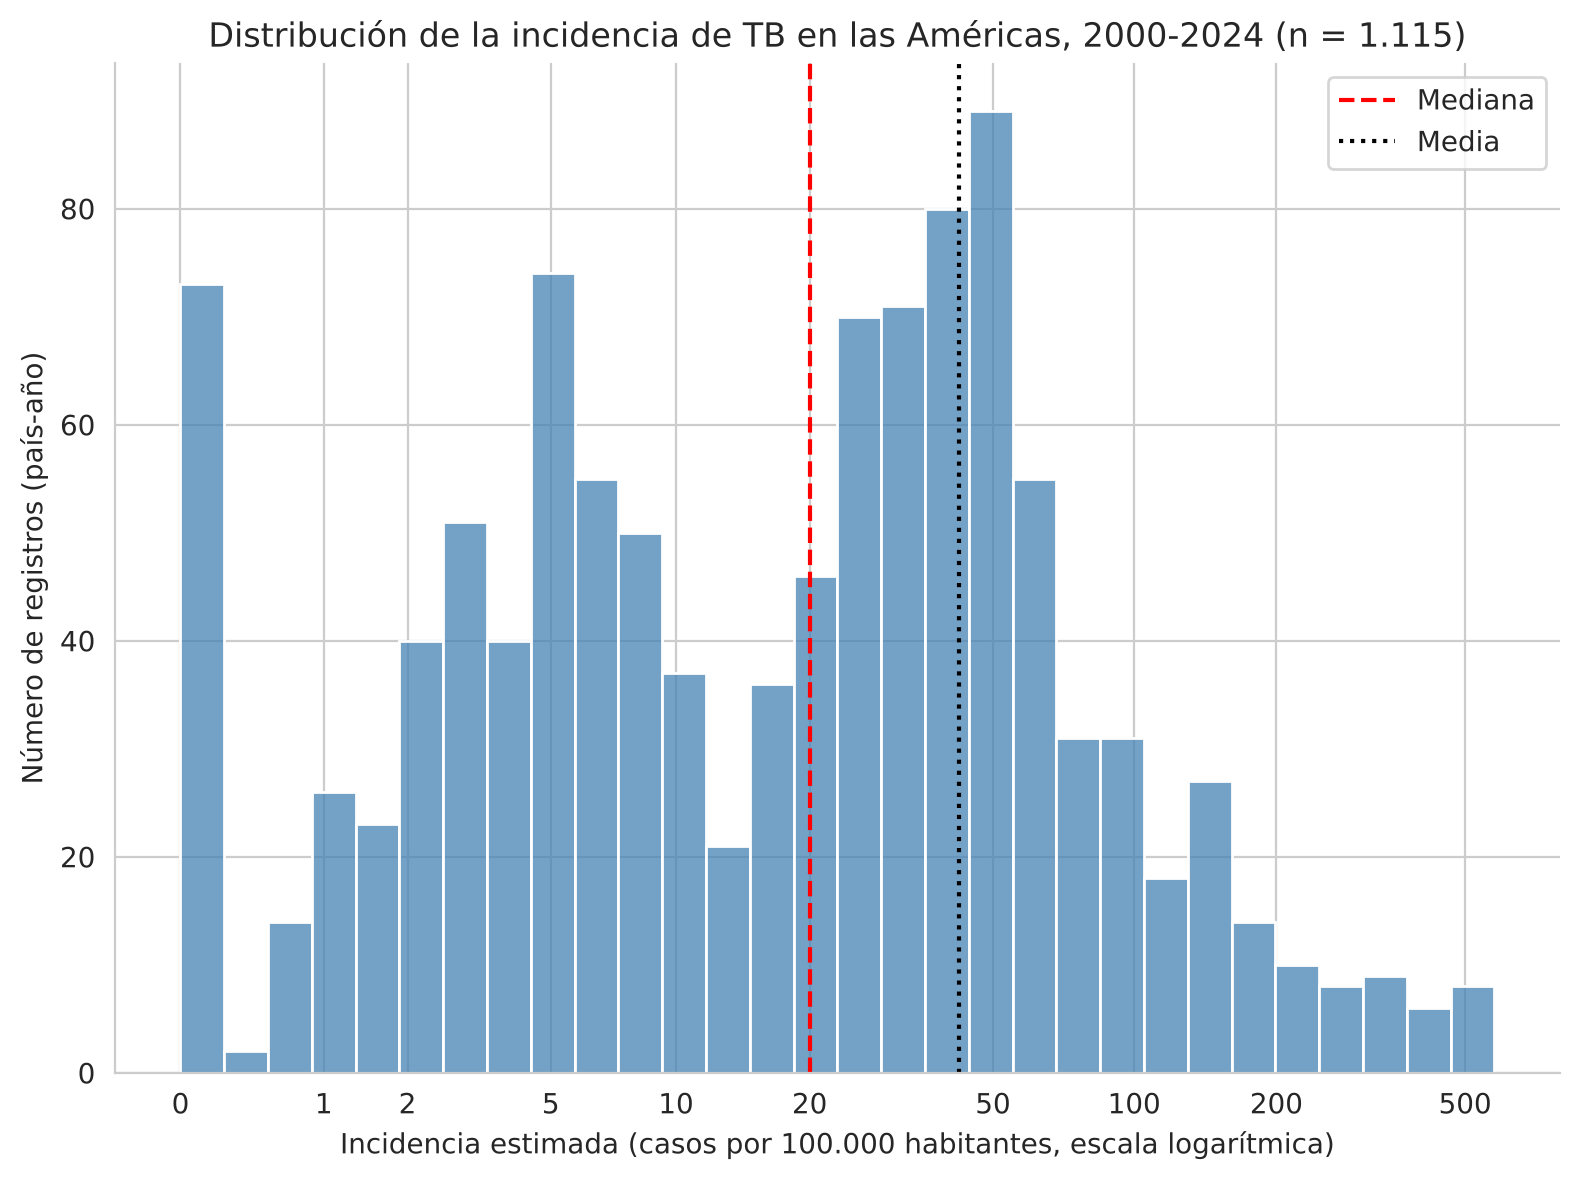

In [30]:
sns.set_style("whitegrid")

# Histograma en escala logarítmica (se suma 1 para poder incluir los ceros)
plt.figure(figsize=(8, 6))
sns.histplot(x=am["incidencia_100k"] + 1,
             bins=30,
             log_scale=True,
             color="steelblue",
             )

plt.axvline(am["incidencia_100k"].median() + 1, color="red", linestyle="--", label="Mediana")
plt.axvline(am["incidencia_100k"].mean() + 1, color="black", linestyle=":", label="Media")

sns.despine()
plt.title("Distribución de la incidencia de TB en las Américas, 2000-2024 (n = 1.115)")
plt.xticks([1, 2, 3, 6, 11, 21, 51, 101, 201, 501],
           ["0", "1", "2", "5", "10", "20", "50", "100", "200", "500"])
plt.xlabel("Incidencia estimada (casos por 100.000 habitantes, escala logarítmica)")
plt.ylabel("Número de registros (país-año)")
plt.legend()
plt.tight_layout()
plt.savefig("figuras/fig1_histograma_incidencia.png", dpi=300)
plt.show()

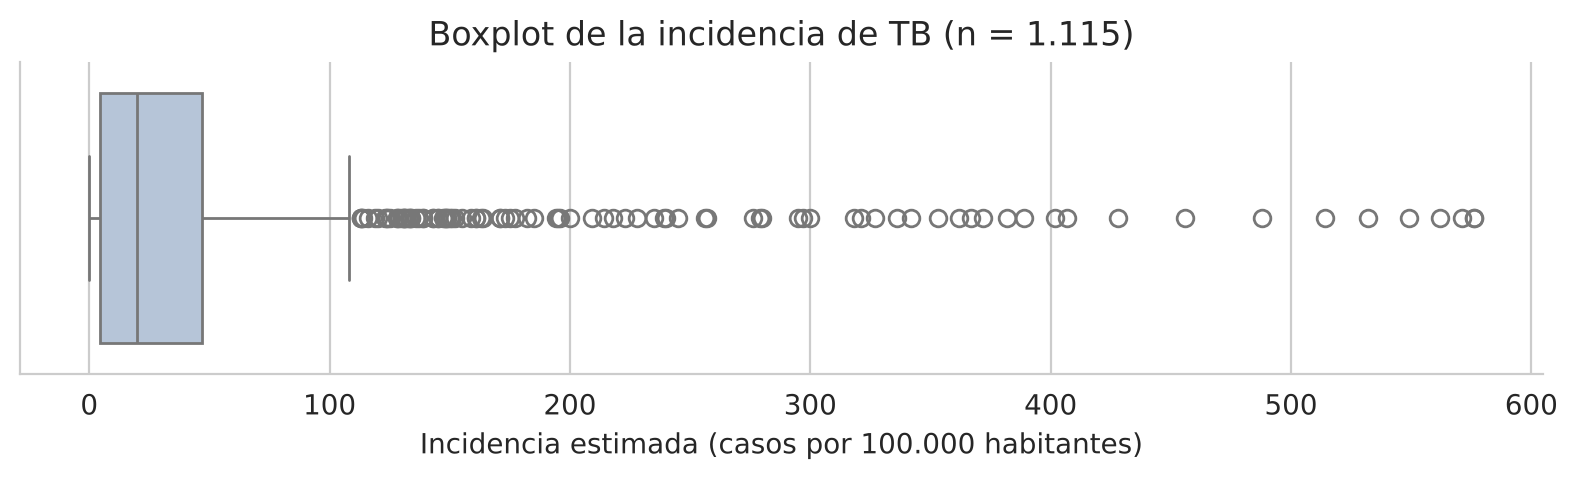

In [31]:
# Boxplot para ver los atípicos
plt.figure(figsize=(8, 2.5))
sns.boxplot(data=am,
            x="incidencia_100k",
            color="lightsteelblue",
            )

sns.despine()
plt.title("Boxplot de la incidencia de TB (n = 1.115)")
plt.xlabel("Incidencia estimada (casos por 100.000 habitantes)")
plt.tight_layout()
plt.savefig("figuras/fig1_boxplot_incidencia.png", dpi=300)
plt.show()

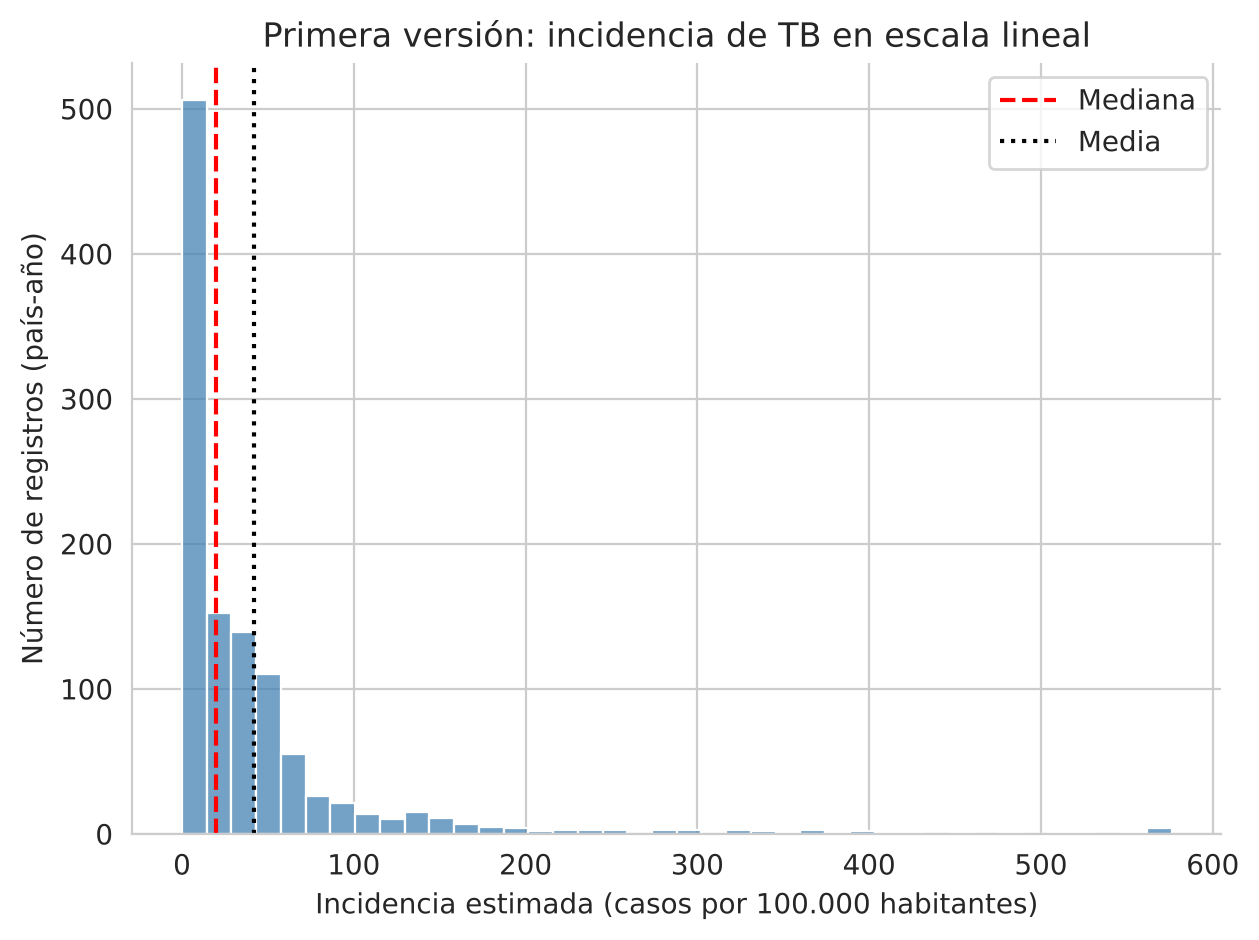

In [32]:
# Primera versión descartada: histograma en escala lineal
sns.histplot(data=am, x="incidencia_100k", bins=40, color="steelblue")
plt.axvline(am["incidencia_100k"].median(), color="red", linestyle="--", label="Mediana")
plt.axvline(am["incidencia_100k"].mean(), color="black", linestyle=":", label="Media")
sns.despine()
plt.title("Primera versión: incidencia de TB en escala lineal")
plt.xlabel("Incidencia estimada (casos por 100.000 habitantes)")
plt.ylabel("Número de registros (país-año)")
plt.legend()
plt.tight_layout()
plt.savefig("figuras/descartadas/fig1_histograma_lineal.png", dpi=200)
plt.show()

In [33]:
# Límite superior de atípicos con la regla de 1,5 x RIC, número de atípicos y países con más atípicos
q1, q3 = am["incidencia_100k"].quantile([0.25, 0.75])
lim_sup = q3 + 1.5 * (q3 - q1)
atip = am["incidencia_100k"] > lim_sup
lim_sup, atip.sum(), am.loc[atip, "pais"].value_counts().head(4).to_dict()

(110.6, np.int64(96), {'Haiti': 25, 'Peru': 25, 'Bolivia': 18, 'Guyana': 14})

In [34]:
# Mediana de la incidencia por subregión
am.groupby("subregion")["incidencia_100k"].median().to_dict()

{'Caribe': 5.2, 'Centroamerica': 42.5, 'Norteamerica': 4.7, 'Sudamerica': 46.0}

### Figura 2. Incidencia por subregión

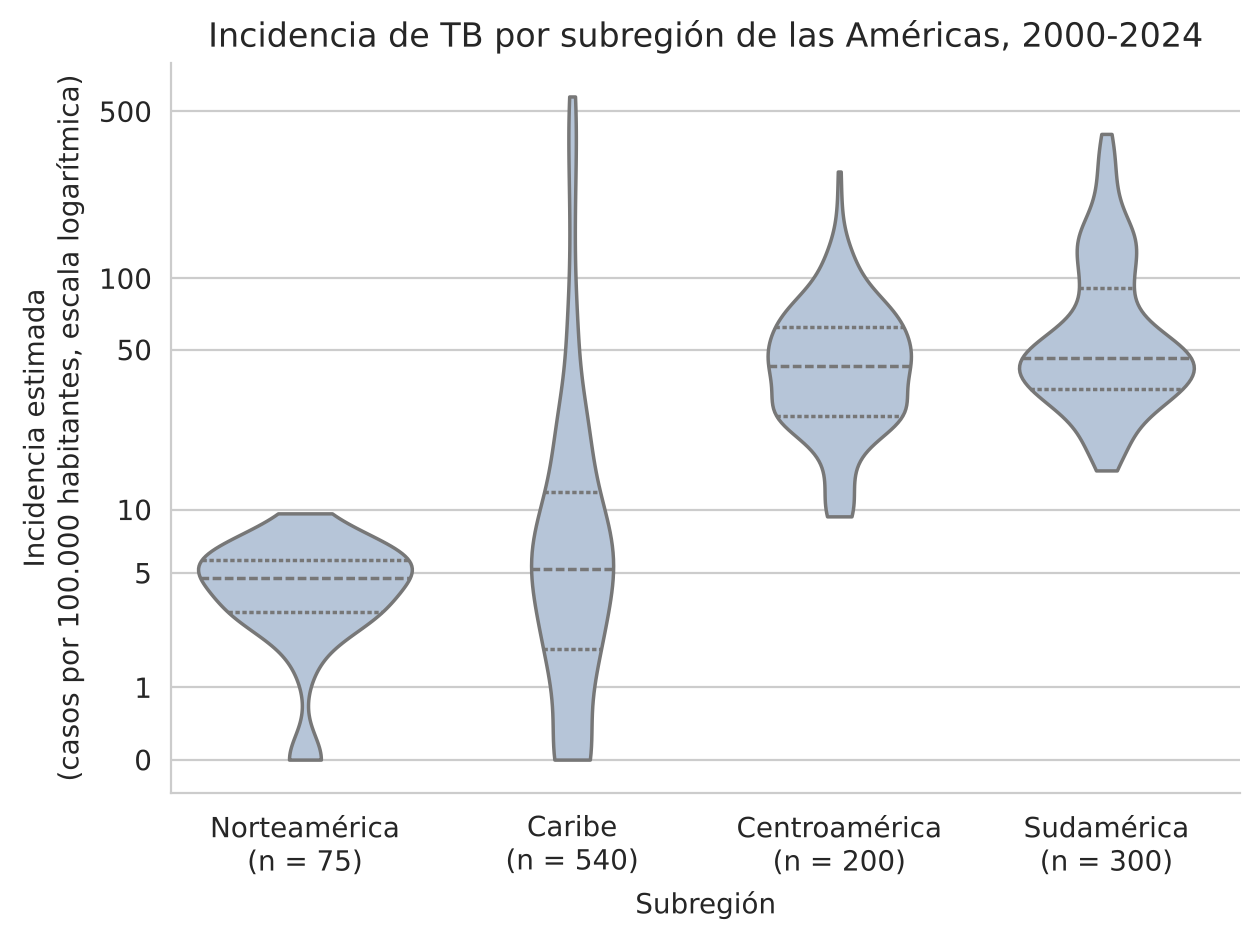

In [35]:
# Orden de las subregiones en las figuras (de menor a mayor mediana)
orden = ["Norteamerica", "Caribe", "Centroamerica", "Sudamerica"]

# Violín de la incidencia por subregión, en escala logarítmica (+1 para incluir los ceros)

sns.violinplot(data=am,
               x="subregion",
               y=am["incidencia_100k"] + 1,
               order=orden,
               log_scale=True,
               inner="quartile",
               cut=0,
               color="lightsteelblue",
               )

sns.despine()
plt.title("Incidencia de TB por subregión de las Américas, 2000-2024")
plt.xticks([0, 1, 2, 3], ["Norteamérica\n(n = 75)", "Caribe\n(n = 540)",
                          "Centroamérica\n(n = 200)", "Sudamérica\n(n = 300)"])
plt.yticks([1, 2, 6, 11, 51, 101, 501], ["0", "1", "5", "10", "50", "100", "500"])
plt.xlabel("Subregión")
plt.ylabel("Incidencia estimada\n(casos por 100.000 habitantes, escala logarítmica)")
plt.tight_layout()
plt.savefig("figuras/fig2_incidencia_subregion.png", dpi=300)
plt.show()

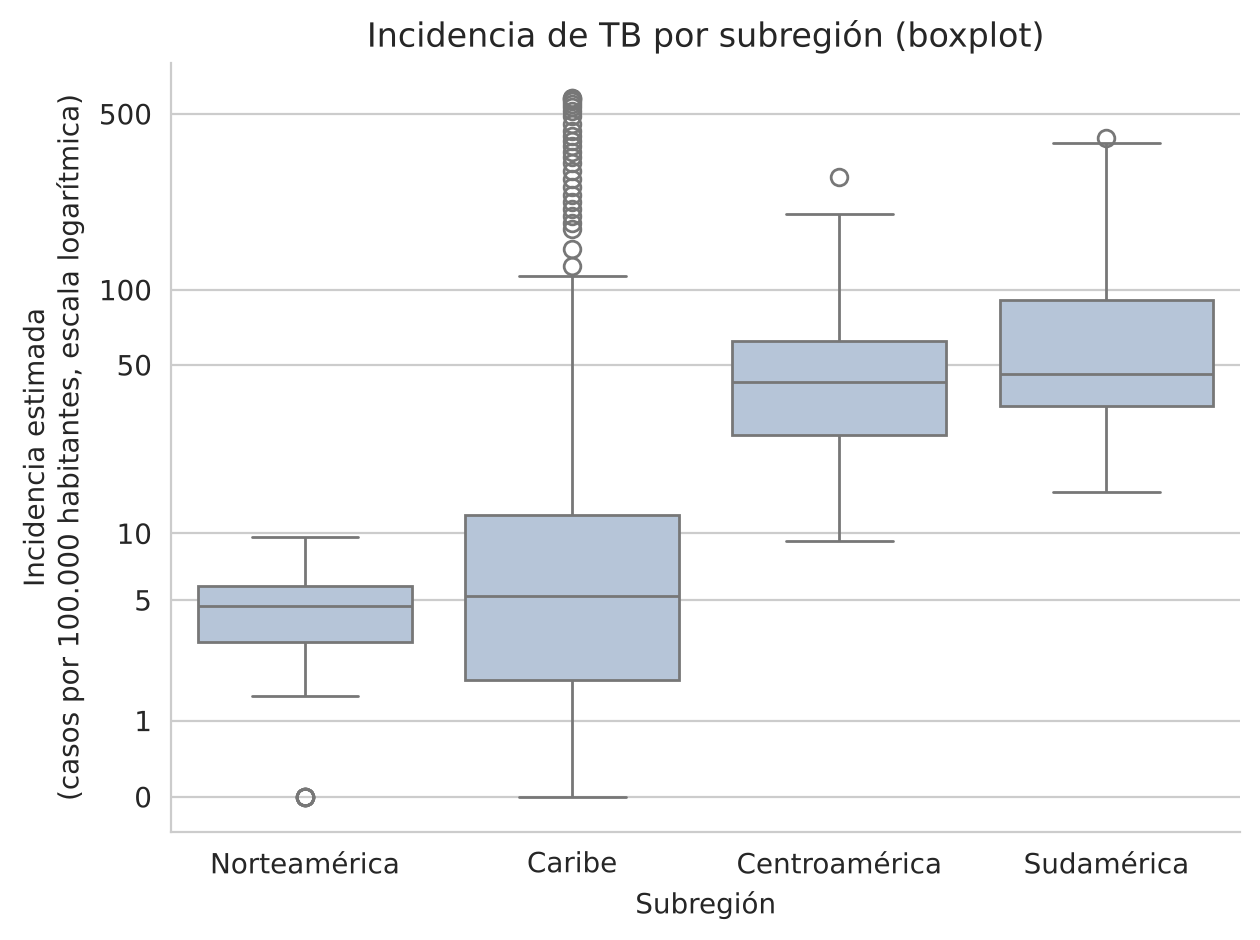

In [36]:
# Alternativa descartada: boxplot por subregión
sns.boxplot(data=am,
            x="subregion",
            y=am["incidencia_100k"] + 1,
            order=orden,
            log_scale=True,
            color="lightsteelblue",
            )

sns.despine()
plt.title("Incidencia de TB por subregión (boxplot)")
plt.xticks([0, 1, 2, 3], ["Norteamérica", "Caribe", "Centroamérica", "Sudamérica"])
plt.yticks([1, 2, 6, 11, 51, 101, 501], ["0", "1", "5", "10", "50", "100", "500"])
plt.xlabel("Subregión")
plt.ylabel("Incidencia estimada\n(casos por 100.000 habitantes, escala logarítmica)")
plt.tight_layout()
plt.savefig("figuras/descartadas/fig2_boxplot_comparacion.png", dpi=200)
plt.show()

In [37]:
# Cuartiles por subregión y países del Caribe con mayor incidencia
(am.groupby("subregion")["incidencia_100k"].describe()[["count", "25%", "50%", "75%"]].round(1),
 am[am["subregion"] == "Caribe"].groupby("pais")["incidencia_100k"].median().nlargest(3).to_dict())

(               count   25%   50%   75%
 subregion                             
 Caribe         540.0   1.9   5.2  12.0
 Centroamerica  200.0  26.0  42.5  62.2
 Norteamerica    75.0   3.1   4.7   5.8
 Sudamerica     300.0  34.0  46.0  91.2,
 {'Haiti': 372.0, 'Dominican Republic': 61.0, 'Trinidad and Tobago': 23.0})

### Figura 3. Relación entre incidencia y mortalidad

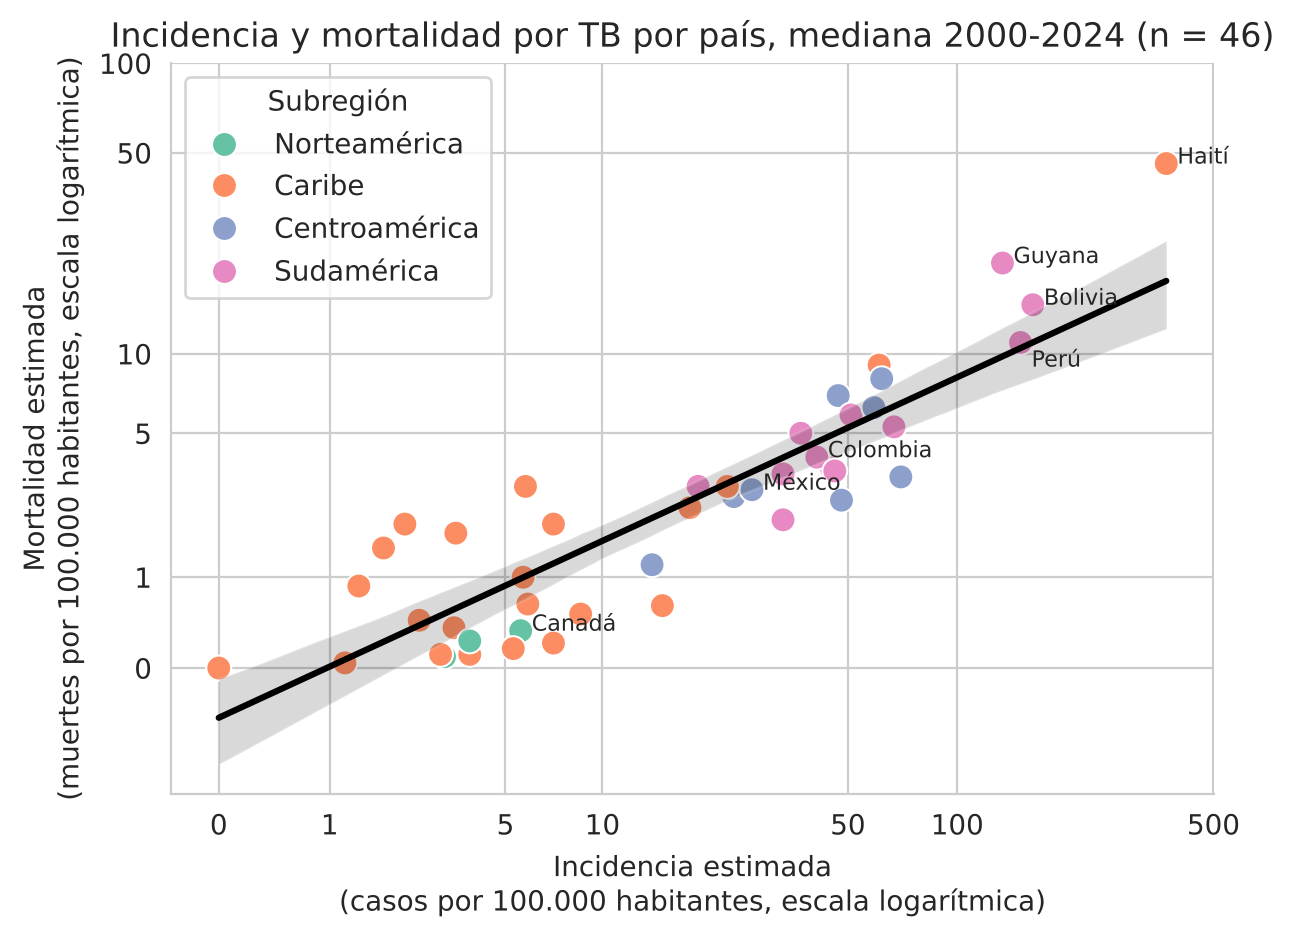

In [38]:
# Mediana de incidencia y mortalidad de cada país (un punto por país)
paises = am.groupby(["pais", "subregion"], as_index=False)[["incidencia_100k", "mortalidad_100k"]].median()

x_pais = np.log10(paises["incidencia_100k"] + 1)
y_pais = np.log10(paises["mortalidad_100k"] + 1)

sns.scatterplot(x=x_pais,
                y=y_pais,
                hue=paises["subregion"],
                hue_order=orden,
                palette="Set2",
                s=80,
                )

sns.regplot(x=x_pais,
            y=y_pais,
            scatter=False,
            color="black",
            )

# Escribir el nombre de algunos países junto a su punto
nombres_es = {"Haiti": "Haití", "Peru": "Perú", "Bolivia": "Bolivia", "Guyana": "Guyana",
              "Colombia": "Colombia", "Canada": "Canadá", "Mexico": "México"}
for i in paises.index:
    pais = paises.loc[i, "pais"]
    if pais in nombres_es:
        dy = -0.08 if pais == "Peru" else 0
        plt.text(x_pais[i] + 0.03, y_pais[i] + dy, nombres_es[pais], fontsize=8)

sns.despine()
plt.title("Incidencia y mortalidad por TB por país, mediana 2000-2024 (n = 46)")
plt.xticks(np.log10([1, 2, 6, 11, 51, 101, 501]), ["0", "1", "5", "10", "50", "100", "500"])
plt.yticks(np.log10([1, 2, 6, 11, 51, 101]), ["0", "1", "5", "10", "50", "100"])
plt.xlabel("Incidencia estimada\n(casos por 100.000 habitantes, escala logarítmica)")
plt.ylabel("Mortalidad estimada\n(muertes por 100.000 habitantes, escala logarítmica)")
puntos, _ = plt.gca().get_legend_handles_labels()
plt.legend(puntos, ["Norteamérica", "Caribe", "Centroamérica", "Sudamérica"], title="Subregión")
plt.tight_layout()
plt.savefig("figuras/fig3_incidencia_mortalidad_paises.png", dpi=300)
plt.show()

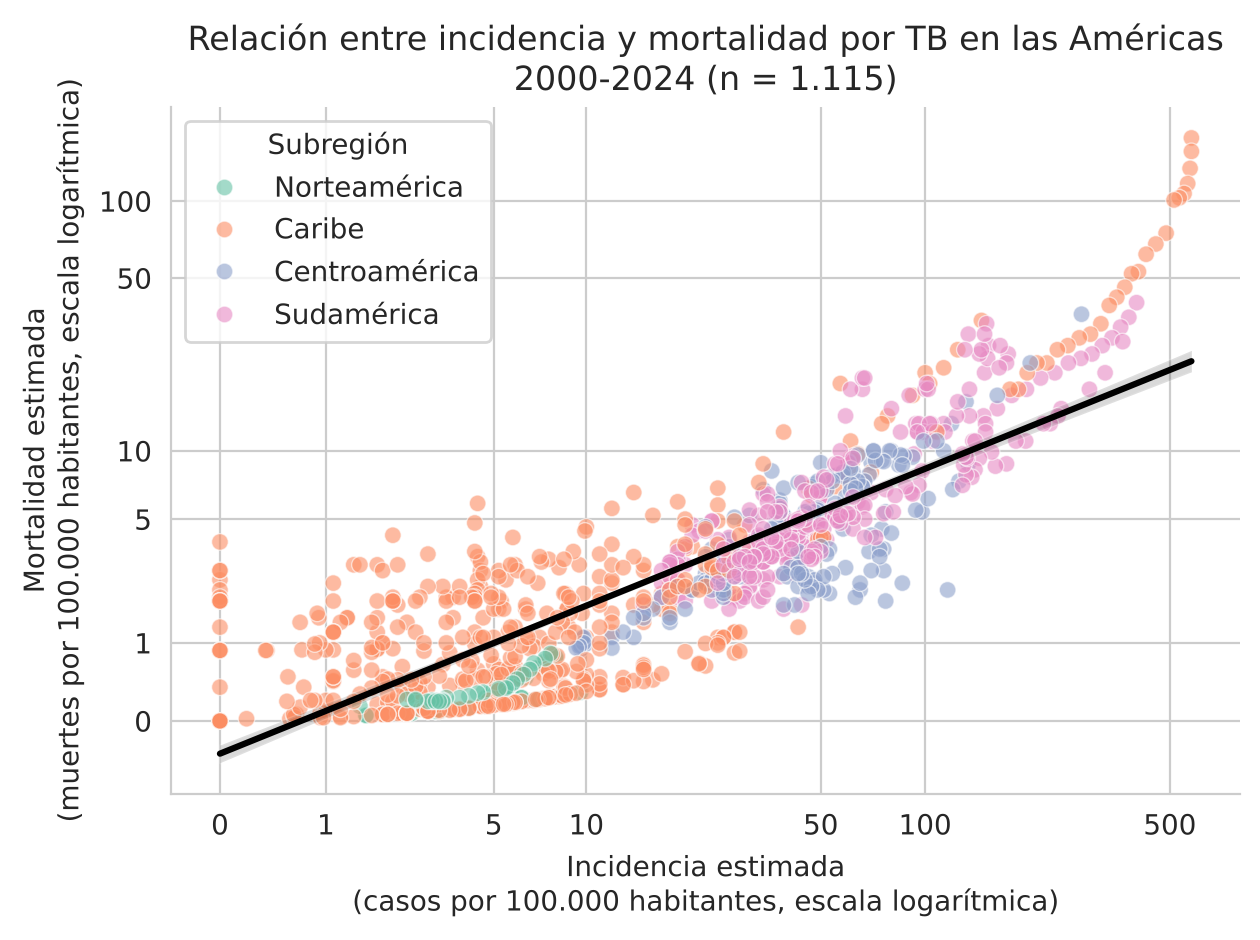

In [39]:
# Primera versión descartada: los 1.115 registros
log_inc = np.log10(am["incidencia_100k"] + 1)
log_mort = np.log10(am["mortalidad_100k"] + 1)

sns.scatterplot(x=log_inc,
                y=log_mort,
                hue=am["subregion"],
                hue_order=orden,
                palette="Set2",
                alpha=0.6,
                )

sns.regplot(x=log_inc,
            y=log_mort,
            scatter=False,
            color="black",
            )

sns.despine()
plt.title("Relación entre incidencia y mortalidad por TB en las Américas\n2000-2024 (n = 1.115)")
plt.xticks(np.log10([1, 2, 6, 11, 51, 101, 501]), ["0", "1", "5", "10", "50", "100", "500"])
plt.yticks(np.log10([1, 2, 6, 11, 51, 101]), ["0", "1", "5", "10", "50", "100"])
plt.xlabel("Incidencia estimada\n(casos por 100.000 habitantes, escala logarítmica)")
plt.ylabel("Mortalidad estimada\n(muertes por 100.000 habitantes, escala logarítmica)")
puntos, _ = plt.gca().get_legend_handles_labels()
plt.legend(puntos, ["Norteamérica", "Caribe", "Centroamérica", "Sudamérica"], title="Subregión")
plt.tight_layout()
plt.savefig("figuras/descartadas/fig3_incidencia_mortalidad_registros.png", dpi=200)
plt.show()

In [40]:
# Correlaciones: un punto por país frente a todos los registros
(round(paises["incidencia_100k"].corr(paises["mortalidad_100k"], method="spearman"), 4), round(x_pais.corr(y_pais), 4),
 round(am["incidencia_100k"].corr(am["mortalidad_100k"], method="spearman"), 4), round(log_inc.corr(log_mort), 4))

(np.float64(0.894), np.float64(0.8894), np.float64(0.8781), np.float64(0.8615))

### Figura 4. Correlaciones entre las variables numéricas

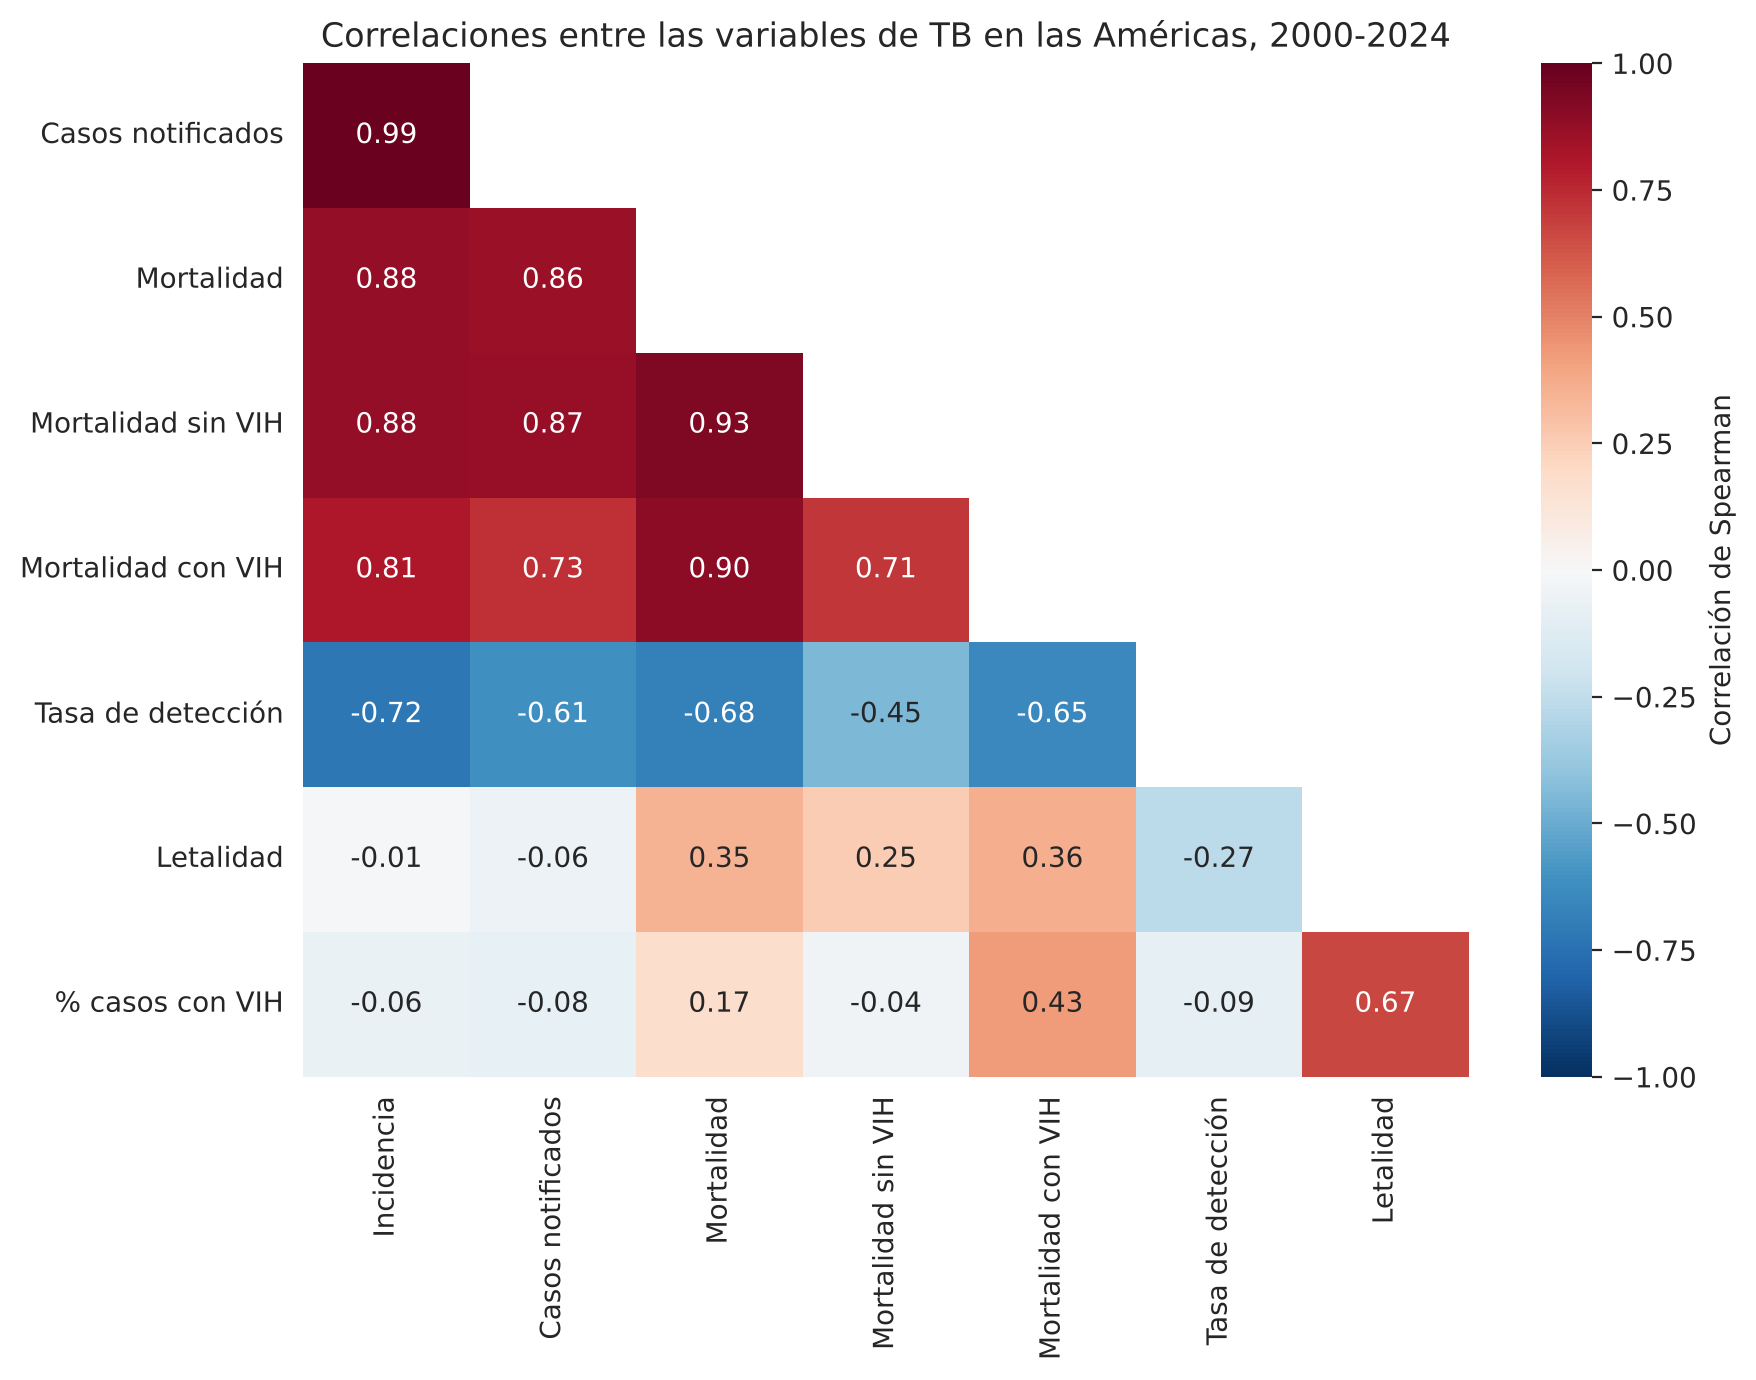

In [41]:
sns.set_style("white")

# Nombres cortos para los ejes del heatmap
etiquetas = {"incidencia_100k": "Incidencia",
             "mortalidad_100k": "Mortalidad",
             "casos_notificados_100k": "Casos notificados",
             "tasa_deteccion": "Tasa de detección",
             "letalidad": "Letalidad",
             "porc_casos_con_vih": "% casos con VIH",
             "mortalidad_con_vih_100k": "Mortalidad con VIH",
             "mortalidad_sin_vih_100k": "Mortalidad sin VIH"}

# Orden de las variables para agrupar las medidas de carga
vars_orden = ["incidencia_100k", "casos_notificados_100k", "mortalidad_100k",
              "mortalidad_sin_vih_100k", "mortalidad_con_vih_100k",
              "tasa_deteccion", "letalidad", "porc_casos_con_vih"]

# Matriz de correlación de Spearman, sin la primera fila, la última columna ni la mitad superior
corr = am[vars_orden].corr(method="spearman").rename(index=etiquetas, columns=etiquetas)
corr = corr.iloc[1:, :-1]
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(9, 7))
sns.heatmap(corr,
            mask=mascara,
            annot=True,
            fmt=".2f",
            cmap="RdBu_r",
            vmin=-1,
            vmax=1,
            center=0,
            cbar_kws={"label": "Correlación de Spearman"},
            )

plt.title("Correlaciones entre las variables de TB en las Américas, 2000-2024")
plt.tight_layout()
plt.savefig("figuras/fig4_heatmap_correlaciones.png", dpi=300)
plt.show()

sns.set_style("whitegrid")

### Figura 5. Evolución de la incidencia en el tiempo (ponderada por población)

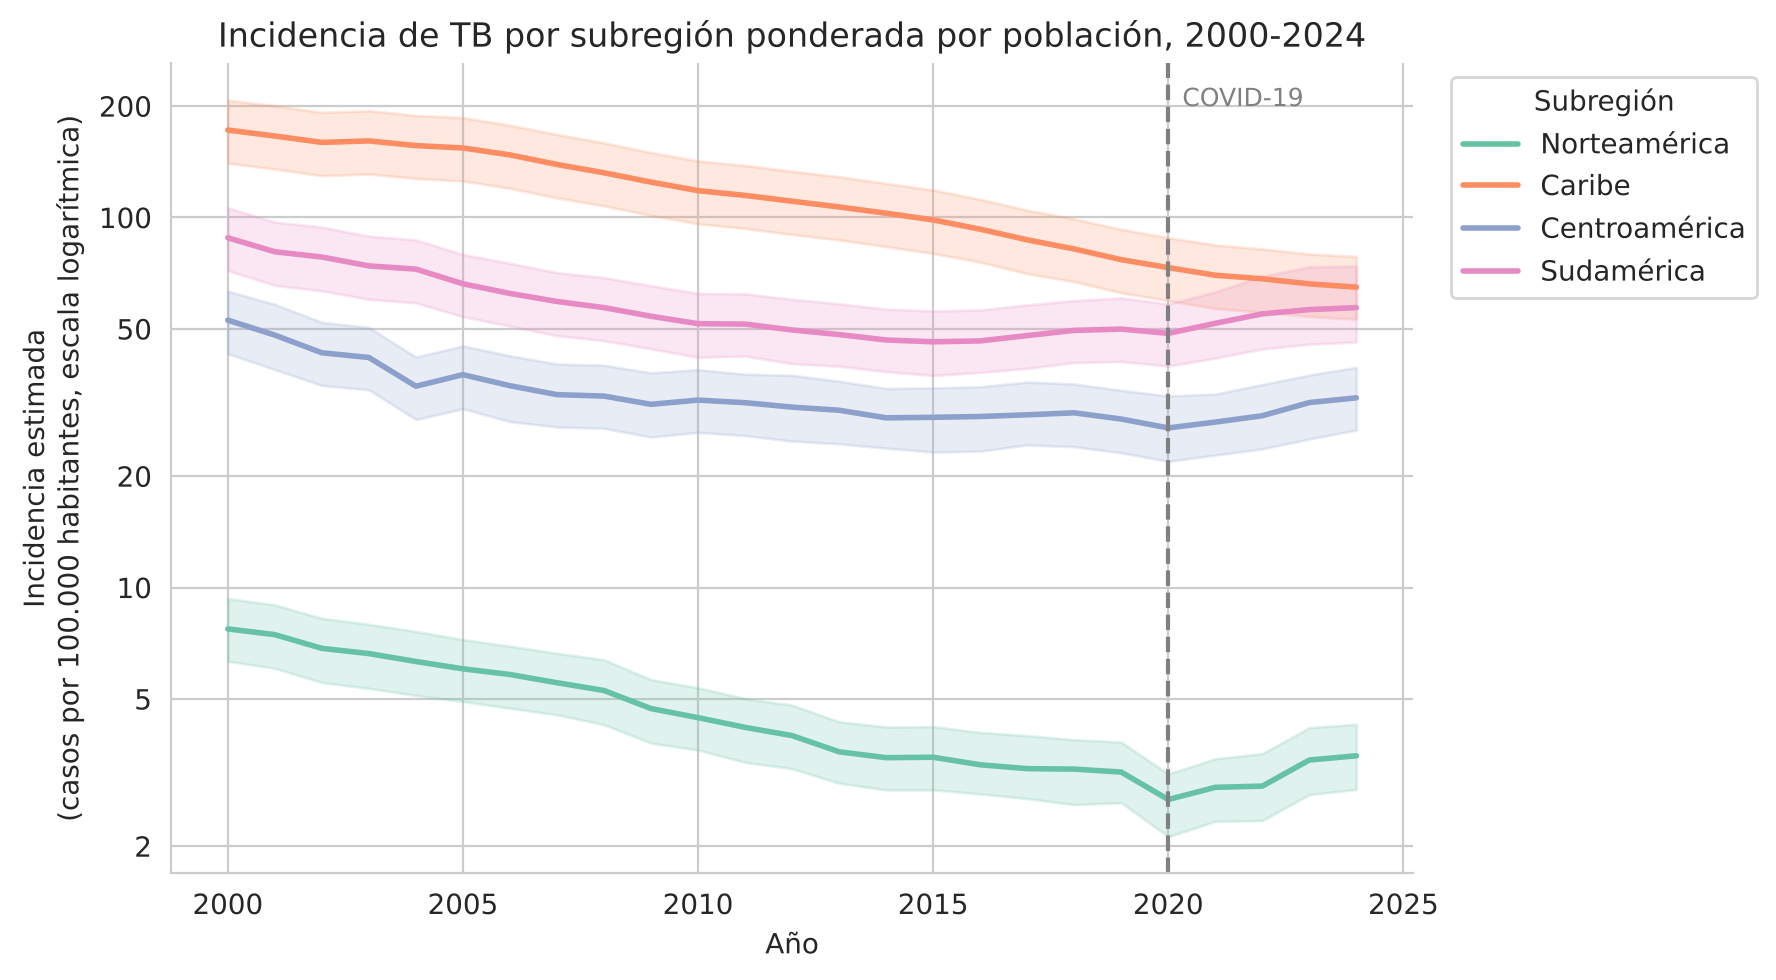

In [42]:
# Incidencia ponderada por población: casos totales / población total de cada subregión y año
tiempo = (am.assign(casos=am["incidencia_100k"] * am["poblacion"],
                    casos_inf=am["incidencia_100k_inf"] * am["poblacion"],
                    casos_sup=am["incidencia_100k_sup"] * am["poblacion"])
            .groupby(["subregion", "anio"], as_index=False)[["casos", "casos_inf", "casos_sup", "poblacion"]]
            .sum())

tiempo["inc"] = tiempo["casos"] / tiempo["poblacion"]
tiempo["inc_inf"] = tiempo["casos_inf"] / tiempo["poblacion"]
tiempo["inc_sup"] = tiempo["casos_sup"] / tiempo["poblacion"]

plt.figure(figsize=(9, 5))

sns.lineplot(data=tiempo,
             x="anio",
             y="inc",
             hue="subregion",
             hue_order=orden,
             palette="Set2",
             linewidth=2,
             )

# Banda de incertidumbre de cada subregión
colores = sns.color_palette("Set2", 4)
for sub, color in zip(orden, colores):
    t = tiempo[tiempo["subregion"] == sub]
    plt.fill_between(t["anio"], t["inc_inf"], t["inc_sup"], color=color, alpha=0.2)

# Línea vertical en el inicio de la pandemia
plt.axvline(2020, color="gray", linestyle="--")
plt.text(2020.3, 200, "COVID-19", color="gray", fontsize=9)

plt.yscale("log")
plt.yticks([2, 5, 10, 20, 50, 100, 200], ["2", "5", "10", "20", "50", "100", "200"])
sns.despine()
plt.title("Incidencia de TB por subregión ponderada por población, 2000-2024")
plt.xlabel("Año")
plt.ylabel("Incidencia estimada\n(casos por 100.000 habitantes, escala logarítmica)")
lineas, _ = plt.gca().get_legend_handles_labels()
plt.legend(lineas, ["Norteamérica", "Caribe", "Centroamérica", "Sudamérica"], title="Subregión",
           loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.savefig("figuras/fig5_evolucion_incidencia.png", dpi=300)
plt.show()

In [43]:
# Incidencia ponderada en 2000 y 2024, y cambio porcentual
t0 = tiempo[tiempo["anio"] == 2000].set_index("subregion")["inc"]
t1 = tiempo[tiempo["anio"] == 2024].set_index("subregion")["inc"]
pd.DataFrame({"2000": t0, "2024": t1, "cambio_%": (t1 / t0 - 1) * 100}).round(1)

,2000,2024,cambio_%
subregion,,,
Caribe,172.3,64.8,-62.4
Centroamerica,52.8,32.5,-38.3
Norteamerica,7.7,3.5,-54.6
Sudamerica,88.1,57.1,-35.3


### Figura 6. Nivel de incidencia por periodo y subregión

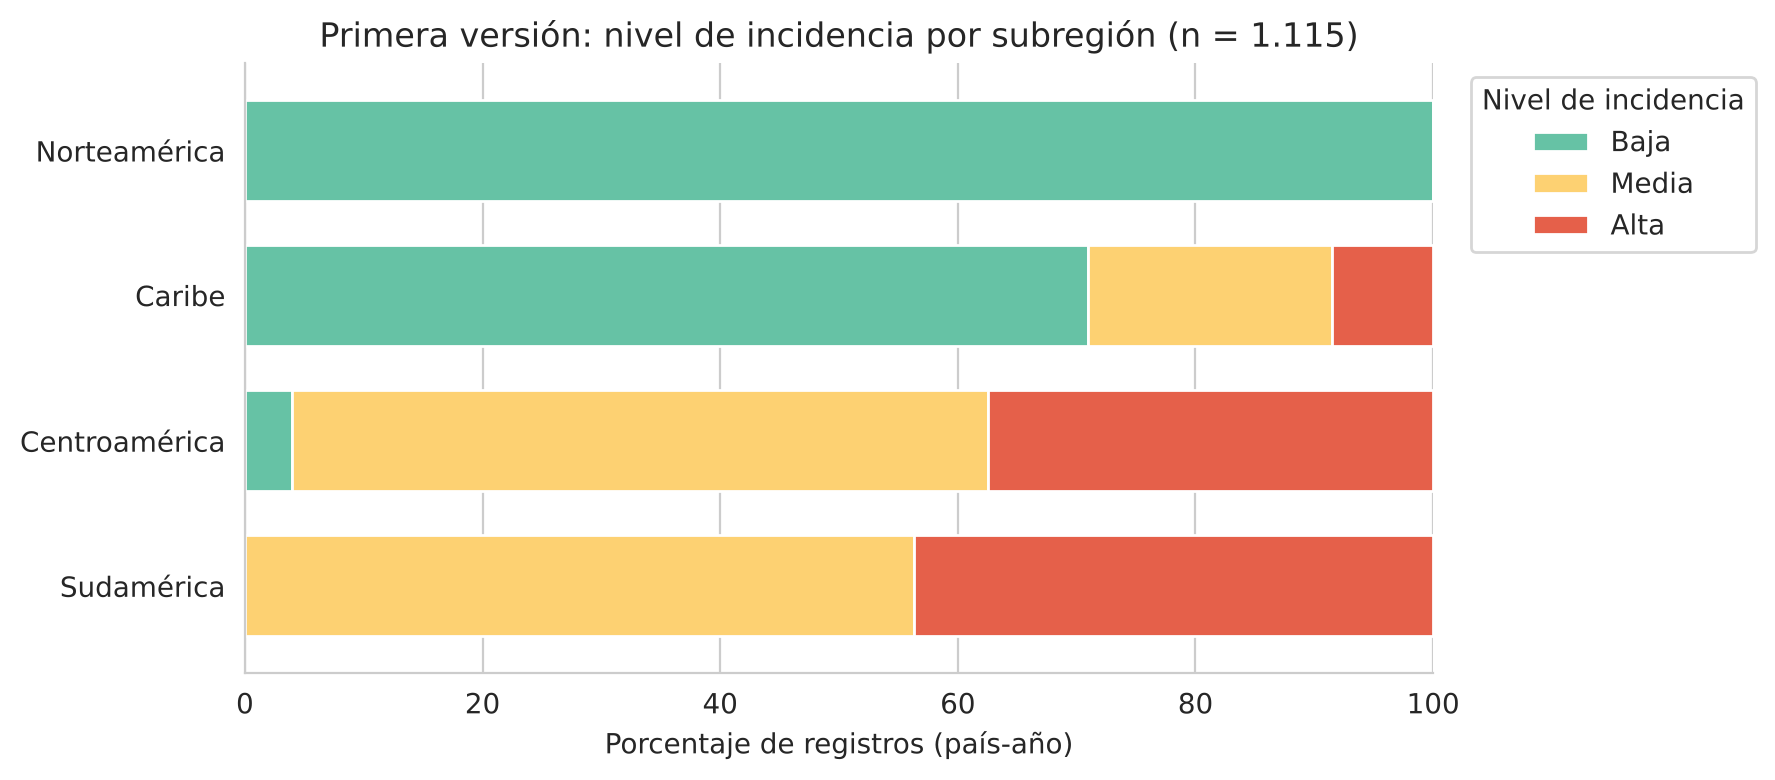

In [44]:
# Primera versión descartada: subregión por nivel de incidencia (repetía lo que muestra la figura 2)
tabla_pct = pd.crosstab(am["subregion"], am["nivel_incidencia"], normalize="index") * 100
tabla_pct = tabla_pct.loc[orden[::-1]]
tabla_pct.index = ["Sudamérica", "Centroamérica", "Caribe", "Norteamérica"]
ax = tabla_pct.plot(kind="barh", stacked=True, color=["#66c2a5", "#fdd172", "#e5604a"],
                    figsize=(9, 4), width=0.7)
sns.despine()
plt.title("Primera versión: nivel de incidencia por subregión (n = 1.115)")
plt.xlabel("Porcentaje de registros (país-año)")
plt.ylabel("")
plt.legend(title="Nivel de incidencia", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.savefig("figuras/descartadas/fig6_subregion_nivel.png", dpi=200)
plt.show()

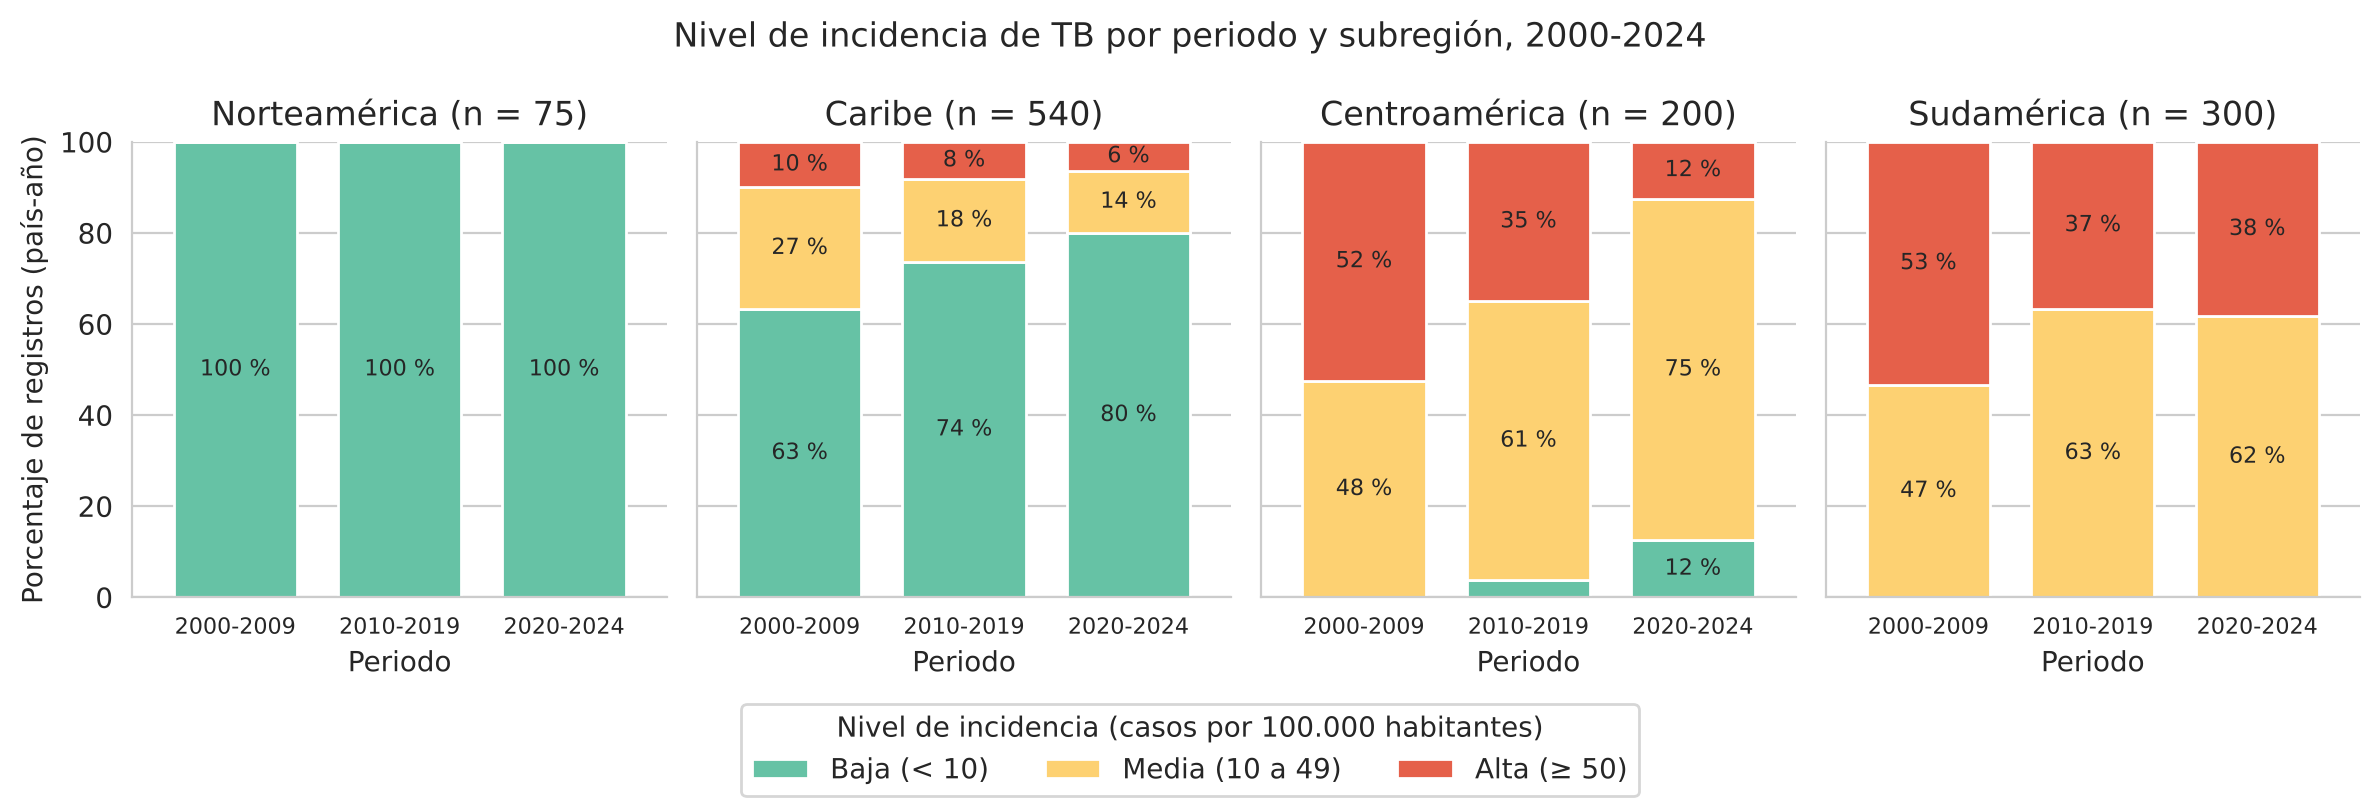

In [45]:
# Un panel por subregión con barras apiladas al 100 % de nivel de incidencia por periodo
nombres_sub = {"Norteamerica": "Norteamérica", "Caribe": "Caribe",
               "Centroamerica": "Centroamérica", "Sudamerica": "Sudamérica"}
colores_nivel = ["#66c2a5", "#fdd172", "#e5604a"]

fig, ejes = plt.subplots(1, 4, figsize=(12, 4), sharey=True)

for ax, sub in zip(ejes, orden):
    # Porcentaje de cada nivel de incidencia por periodo en la subregión
    datos_sub = am[am["subregion"] == sub]
    t = pd.crosstab(datos_sub["periodo"], datos_sub["nivel_incidencia"], normalize="index") * 100
    t = t.reindex(columns=["Baja", "Media", "Alta"], fill_value=0)

    t.plot(kind="bar", stacked=True, ax=ax, color=colores_nivel, width=0.75, legend=False)

    # Escribir los porcentajes dentro de cada segmento (si cabe)
    for barras in ax.containers:
        ax.bar_label(barras,
                     labels=[f"{v:.0f} %" if v >= 6 else "" for v in barras.datavalues],
                     label_type="center",
                     fontsize=8)

    ax.set_title(f"{nombres_sub[sub]} (n = {len(datos_sub)})")
    ax.set_xlabel("Periodo")
    ax.tick_params(axis="x", rotation=0, labelsize=8)

sns.despine()
ejes[0].set_ylabel("Porcentaje de registros (país-año)")
# Una sola leyenda para toda la figura
barras_leyenda, _ = ejes[0].get_legend_handles_labels()
fig.legend(barras_leyenda, ["Baja (< 10)", "Media (10 a 49)", "Alta (≥ 50)"],
           title="Nivel de incidencia (casos por 100.000 habitantes)",
           loc="lower center", ncol=3)
fig.suptitle("Nivel de incidencia de TB por periodo y subregión, 2000-2024")
plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.savefig("figuras/fig6_nivel_periodo_subregion.png", dpi=300)
plt.show()

In [46]:
# Asociación entre periodo y nivel de incidencia: chi-cuadrado, valor p y V de Cramér
tabla = pd.crosstab(am["periodo"], am["nivel_incidencia"])
chi2, p, gl, esperados = chi2_contingency(tabla)
round(chi2, 1), p, round(np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1))), 2)

(np.float64(19.1), np.float64(0.0007521908253547952), np.float64(0.09))

## 11. Conclusiones

- La tuberculosis se distribuye de forma muy desigual: Centroamérica y Sudamérica tienen una incidencia mucho mayor que Norteamérica y la mayoría del Caribe, y los valores más altos se concentran en Haití, Perú, Bolivia y Guyana.
- Entre 2000 y 2024 la incidencia bajó en todas las subregiones, pero Sudamérica dejó de mejorar hacia 2015 y varias subregiones muestran un aumento desde 2020.
- Los países con más casos también tienen más muertes, y la proporción de personas que mueren se asocia más con la coinfección con VIH que con la cantidad de casos.
- La forma de resumir los datos cambia las conclusiones: al ponderar por población, el Caribe pasa a ser la subregión con mayor incidencia.